In [1]:
!pip install numpy
!pip install matplotlib
!pip install pandas
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates


In [2]:
import pandas as pd

cols = [
    "burst",        # Burst counter
    "ensemble",     # Ensemble counter (1-65536)
    "w",            # Velocity Beam1|X|East (m/s) orginally u renamed to w to reflect vertical velocities
    "u",            # Velocity Beam2|Y|North (m/s) originally v now renamed to u to reflect crossh shore velocities
    "v",            # Velocity Beam3|Z|Up (m/s) orginally w now renamed to v to reflect alongshore velocities
    "amp1",         # Amplitude Beam1 (counts)
    "amp2",         # Amplitude Beam2 (counts)
    "amp3",         # Amplitude Beam3 (counts)
    "snr1",         # SNR Beam1 (dB)
    "snr2",         # SNR Beam2 (dB)
    "snr3",         # SNR Beam3 (dB)
    "corr1",        # Correlation Beam1 (%)
    "corr2",        # Correlation Beam2 (%)
    "corr3",        # Correlation Beam3 (%)
    "pressure",     # Pressure (dbar)
    "analog1",      # Analog input 1
    "analog2",      # Analog input 2
    "checksum",     # Checksum (1 = failed)
]

#U=cross shore velocity
#V=along shore velocity 
#W=vertical velocity


df_SSC01 = pd.read_csv("SSC01.dat", sep=r"\s+", header=None, names=cols)
df_SSC02L = pd.read_csv("SSC02A.dat", sep=r"\s+", header=None, names=cols)
df_SSC02H = pd.read_csv("SSC02B.dat", sep=r"\s+", header=None, names=cols)

In [3]:
df_SSC01["t"] = df_SSC01.index / 16                     #Data from first field compain on 29 september
start = pd.Timestamp("2026-09-29 06:00:00")
df_SSC01["time"] = start + pd.to_timedelta(df_SSC01["t"], unit="s")

df_SSC02L["t"] = df_SSC02L.index / 16.                  #Data from second field compain on 2 oktober from the lowest sensor
start = pd.Timestamp("2026-10-02 06:00:00")
df_SSC02L["time"] = start + pd.to_timedelta(df_SSC02L["t"], unit="s")

df_SSC02H["t"] = df_SSC02H.index / 16                   #Data from second field compain on 2 oktober from the highest sensor
start = pd.Timestamp("2026-10-02 06:00:00")
df_SSC02H["time"] = start + pd.to_timedelta(df_SSC02H["t"], unit="s")

In [4]:
manoeuvres = {    
    "B1-51": "10:07:17",
    "B1-52": "10:12:18",
    "B1-53": "10:15:24 ",
    "B1-54": "10:18:58",
    "B2-51": "10:23:29", 
    "B2-52": "10:27:08",
    "B2-53": "10:31:06",
    "B2-54": "10:35:09", 
    "B3-51": "10:38:24", 
    "B3-52": "10:43:29", 
    "B3-53": "10:48:18",
    "B3-54": "10:51:30",
    "B4-61": "11:05:02", 
    "B4-62": "11:08:01", 
    "B4-63": "11:10:58", 
    "B4-64": "11:14:23", 
    "A1-61": "11:18:17", 
    "A1-62": "11:20:39", 
    "A1-63": "11:23:01",
    "A2-61": "11:25:51", 
    "A2-62": "11:28:17", 
    "F-71": ["11:31:10", "11:32:03", "11:32:57", "11:33:55"],
    "B3-81": "11:00:24"
}
df = df_SSC02L
DAY = start.strftime("%Y-%m-%d")   


In [5]:
import matplotlib.dates as mdates

def despike(s, window=101, k=4):
    med = s.rolling(window, center=True, min_periods=1).median()
    dev = s - med
    return s.where(dev.abs() <= k * dev.std())

def plot_uvw(data, start, end, window=101, k=4, filter_peaks=True):
    t_start = pd.Timestamp(f"{DAY} {start}")
    t_end   = pd.Timestamp(f"{DAY} {end}")

    part = data[(data["time"] >= t_start) & (data["time"] <= t_end)].copy()

    if filter_peaks:
        for comp in ["u", "v", "w"]:
            before = part[comp].notna().sum()
            part[comp] = despike(part[comp], window, k)
            print(f"{comp}: removed {before - part[comp].notna().sum()} peaks")

    fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
    for ax, comp in zip(axes, ["corr1", "corr2", "corr3"]):
        ax.plot(part["time"], part[comp], lw=0.3, alpha=0.4, label="raw")
        ax.set_ylabel(comp)
        ax.grid(True, alpha=0.3)
    axes[-1].set_xlabel("Time (HH:MM)")

    for name, t in manoeuvres.items():
        if isinstance(t, str):
            t = [t]
        xs = [pd.Timestamp(f"{DAY} {x}") for x in t]
        xs = [x for x in xs if t_start <= x <= t_end]
        if not xs:
            continue
        for x in xs:
            for ax in axes:
                ax.axvline(x, color="k", ls="--", lw=0.6)
        mid = xs[0] + (xs[-1] - xs[0]) / 2
        axes[0].text(mid, 1.01, name, transform=axes[0].get_xaxis_transform(),
                     rotation=90, ha="center", va="bottom", fontsize=12)

    axes[-1].set_xlim(t_start, t_end)
    axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
    plt.tight_layout()
    plt.show()

In [6]:
def plot_sediment(data, start, end, window=101, k=4, filter_peaks=True, corr_limit=62):
    """Plot analog1 between two times.

    corr_limit: analog1 values are removed where corr1 (%) is below this limit;
                the removed values are shown in red. None = no correlation filter.
    """
    t_start = pd.Timestamp(f"{DAY} {start}")
    t_end   = pd.Timestamp(f"{DAY} {end}")

    part = data[(data["time"] >= t_start) & (data["time"] <= t_end)].copy()

    comp = "analog1"
    corr = "corr1"

    # correlation filter -- works on the copy, so the original data is not changed
    removed = None
    if corr_limit is not None:
        bad = part[corr] < corr_limit
        removed = part.loc[bad, ["time", comp, corr]].copy()   # the values before blanking
        part.loc[bad, comp] = np.nan
        print(f"{comp}: removed {bad.sum()} of {len(part)} values with {corr} < {corr_limit}%")

    if filter_peaks:
        before = part[comp].notna().sum()
        part[comp] = despike(part[comp], window, k)
        print(f"{comp}: removed {before - part[comp].notna().sum()} peaks")

    if corr_limit is not None:
        # top: correlation with the limit, bottom: analog1
        fig, (ax_corr, ax) = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
        axes = [ax_corr, ax]
        ax_corr.plot(part["time"], part[corr], lw=0.3, alpha=0.4, label=corr)
        ax_corr.plot(removed["time"], removed[corr], ls="none", marker=".", ms=3,
                     color="red", label="below limit")
        ax_corr.axhline(corr_limit, color="red", ls="--", lw=0.8)
        ax_corr.set_ylabel(f"{corr} (%)")
        ax_corr.grid(True, alpha=0.3)
        ax_corr.legend(loc="lower right")
    else:
        fig, ax = plt.subplots(figsize=(12, 4))
        axes = [ax]

    ax.plot(part["time"], part[comp], lw=0.3, alpha=0.4, label="kept")
    if removed is not None:
        ax.plot(removed["time"], removed[comp], ls="none", marker=".", ms=3,
                color="red", label="removed (low correlation)")
        ax.legend(loc="upper right")
    ax.set_ylabel(comp)
    ax.set_xlabel("Time (HH:MM)")
    ax.grid(True, alpha=0.3)

    for name, t in manoeuvres.items():
        if isinstance(t, str):
            t = [t]
        xs = [pd.Timestamp(f"{DAY} {x}") for x in t]
        xs = [x for x in xs if t_start <= x <= t_end]
        if not xs:
            continue
        for x in xs:
            for a in axes:
                a.axvline(x, color="k", ls="--", lw=0.6)
        mid = xs[0] + (xs[-1] - xs[0]) / 2
        axes[0].text(mid, 1.01, name, transform=axes[0].get_xaxis_transform(),
                     rotation=90, ha="center", va="bottom", fontsize=12)

    ax.set_xlim(t_start, t_end)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
    plt.tight_layout()
    plt.show()

analog1: removed 139167 of 316801 values with corr1 < 62%


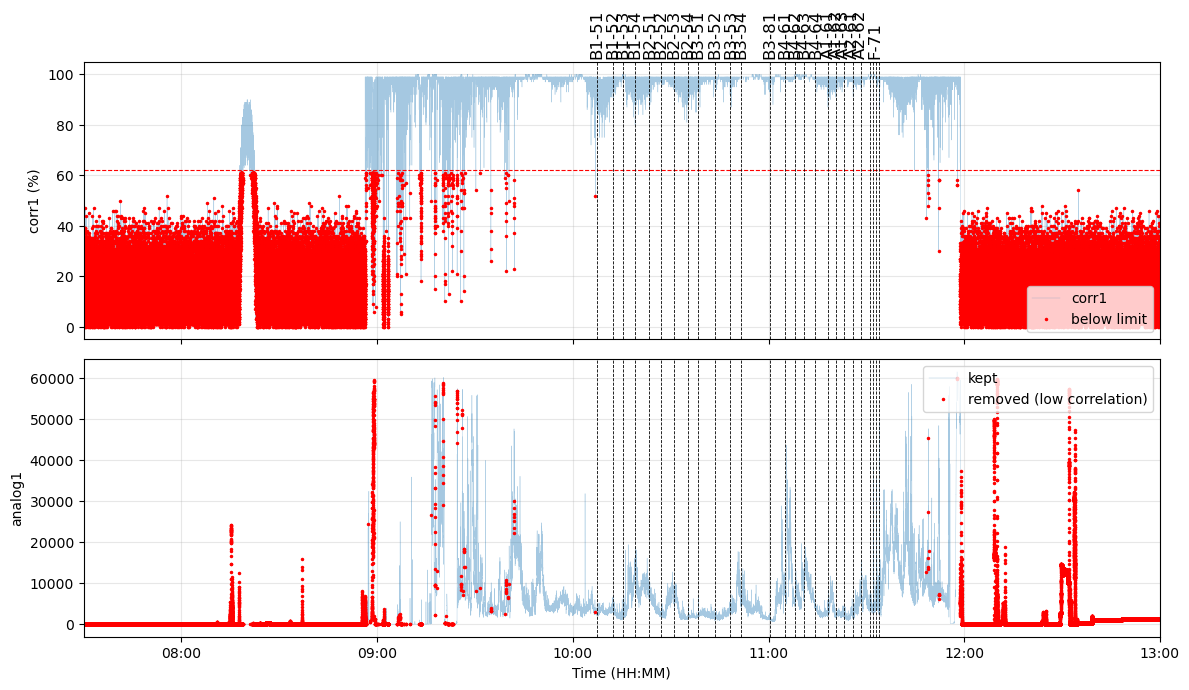

In [7]:
#plot_uvw(df, "10:00", "11:10", filter_peaks=False)
#plot_uvw(df, "08:00", "09:30", filter_peaks=False)              # stricter peak filter
#plot_uvw(df, "08:00", "09:30", filter_peaks=False)  # no filtering

CORR_LIMIT = 62    # percent; from 0.3 + 0.4 * sqrt(16/25) = 0.62 for 16 Hz

plot_sediment(df, "07:30", "13:00", filter_peaks=False, corr_limit=CORR_LIMIT)
#plot_sediment(df, "07:30", "11:00", filter_peaks=False, corr_limit=None)   # no correlation filter

[]

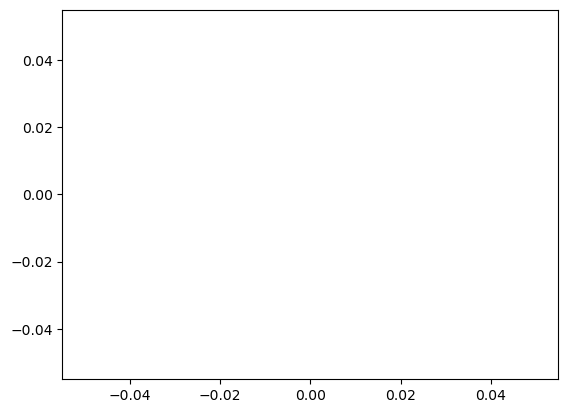

In [8]:
plt.plot()

<a style='text-decoration:none;line-height:16px;display:flex;color:#5B5B62;padding:10px;justify-content:end;' href='https://deepnote.com?utm_source=created-in-deepnote-cell&projectId=cb8feeb3-afee-4b20-ab89-f0abd9348b44' target="_blank">

Created in <span style='font-weight:600;margin-left:4px;'>Deepnote</span></a>